# 02 · Demand forecasting and changepoints

**Question.** How much interest is there in Smiskis, where is it heading, and *when* did the craze actually change gear?

**Plan**
1. Weekly search interest ("smiski"), with product events overlaid.
2. Forecast with six models: naive, seasonal-naive, SARIMAX, Prophet, Prophet + launch calendar, LightGBM on lags.
3. Judge them on **rolling-origin backtests** (to choose) and on a **held-out final 52 weeks** (to report).
4. Detect changepoints with `ruptures` and line them up with product events.
5. Forecast the next 26 weeks with an interval.

Baselines come first: if a fancy model can't beat "same as last week" or "same as this week last year", it's not earning its keep.

In [1]:
import sys, pathlib, warnings, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ruptures as rpt
import lightgbm as lgb
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
import logging; logging.getLogger("cmdstanpy").setLevel(logging.ERROR); logging.getLogger("prophet").setLevel(logging.ERROR)

from smiskis.data import load, banner, provenance
from smiskis.paths import SITE_DATA, ROOT as PROJECT, AS_OF
from smiskis import viz
viz.set_style()
FIG = PROJECT / "reports"; FIG.mkdir(exist_ok=True)
print(banner("trends", "events", "series"))

trends, events, series = load("trends"), load("events"), load("series")
trends = trends.sort_values("week").reset_index(drop=True)
weeks = pd.DatetimeIndex(trends["week"])
y = np.maximum(trends["interest"].astype(float).values, 0.5)     # Google rounds tiny values to 0; floor so logs are defined
ly = np.log(y)
HOLD, H_BT, PERIOD = 52, 26, 365.25 / 7
print(f"{len(y)} weekly points  {weeks[0].date()} -> {weeks[-1].date()}  holdout = last {HOLD} weeks")

DATA PROVENANCE  [trends: scraped | events: scraped | series: scraped]
459 weekly points  2017-12-31 -> 2026-10-11  holdout = last 52 weeks


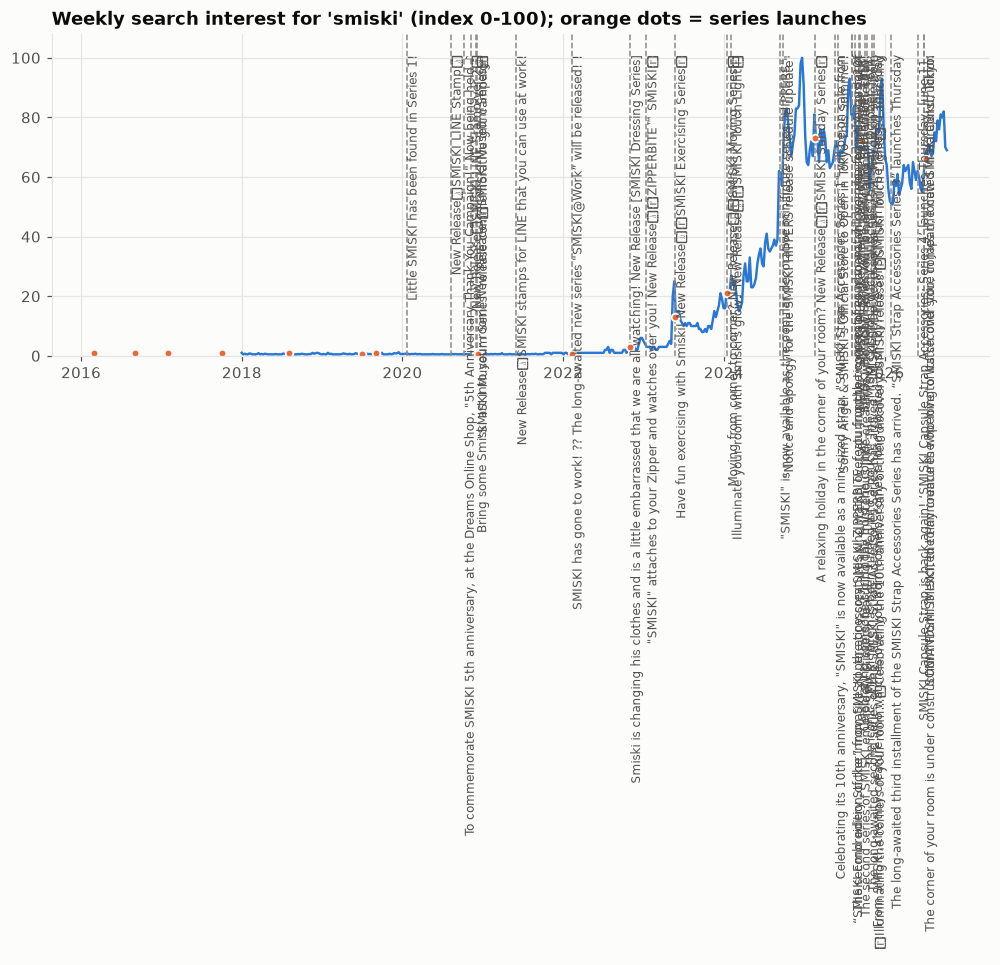

In [2]:
launch_dates = pd.DatetimeIndex(series["release_date"])

def launch_features(idx):
    """Known-in-advance product calendar: decayed launch effect + weeks since last launch."""
    dec, since = np.zeros(len(idx)), np.zeros(len(idx))
    for i, d in enumerate(idx):
        w = np.asarray((d - launch_dates).days) / 7.0
        dec[i] = np.exp(-w[w >= 0] / 3.0).sum()
        since[i] = w[w >= 0].min() if (w >= 0).any() else 99
    return dec, np.minimum(since, 26)

def fourier(idx, K=2):
    t = (idx - pd.Timestamp("2018-01-01")).days.values / 7.0
    cols = {}
    for k in range(1, K + 1):
        cols[f"s{k}"] = np.sin(2 * np.pi * k * t / PERIOD); cols[f"c{k}"] = np.cos(2 * np.pi * k * t / PERIOD)
    return pd.DataFrame(cols, index=idx)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(weeks, y, color=viz.SERIES[0], lw=1.6)
for _, e in events[events.type != "series_launch"].iterrows():
    ax.axvline(e["date"], color=viz.NEUTRAL, lw=1, ls="--"); ax.text(e["date"], 101, " " + e["label"].split("(")[0].strip(), rotation=90, va="top", fontsize=8, color=viz.INK2)
for d in launch_dates: ax.plot([d], [y[weeks.get_indexer([d], method="nearest")[0]]], marker="o", ms=5, color=viz.SERIES[1], mec=viz.SURFACE, mew=1.2, ls="")
ax.set_title("Weekly search interest for 'smiski' (index 0-100); orange dots = series launches"); ax.set_ylim(0, 108)
plt.tight_layout(); plt.savefig(FIG / "forecast_history.png", dpi=150); plt.show()

## 1 · Forecasters

Every forecaster has the signature `f(train_index, train_values, horizon) -> (mean, lo, hi)` on the **original 0-100 scale**; `lo/hi` is an 80% interval or `None`.

In [3]:
def f_naive(idx, v, h):
    return np.full(h, v[-1]), None, None

def f_seasonal_naive(idx, v, h):
    s = 52
    base = v[-s:]
    return np.array([base[i % s] for i in range(h)]), None, None

def _future_idx(idx, h):
    return pd.date_range(idx[-1] + pd.Timedelta(weeks=1), periods=h, freq="W-SUN")

def f_sarimax(idx, v, h):
    fi = _future_idx(idx, h)
    m = SARIMAX(np.log(v), exog=fourier(idx).values, order=(1, 1, 1), trend="n",
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
    fc = m.get_forecast(h, exog=fourier(fi).values)
    ci = fc.conf_int(alpha=0.2)
    return np.exp(fc.predicted_mean), np.exp(ci[:, 0]), np.exp(ci[:, 1])

def _prophet(idx, v, h, events_on):
    fi = _future_idx(idx, h)
    df = pd.DataFrame({"ds": idx, "y": np.log(v)})
    m = Prophet(yearly_seasonality=4, weekly_seasonality=False, daily_seasonality=False, changepoint_prior_scale=0.15,
                interval_width=0.8, mcmc_samples=0)
    if events_on:
        df["launch"] = launch_features(idx)[0]; m.add_regressor("launch")
    m.fit(df)
    fut = pd.DataFrame({"ds": fi})
    if events_on: fut["launch"] = launch_features(fi)[0]
    p = m.predict(fut)
    return np.exp(p["yhat"].values), np.exp(p["yhat_lower"].values), np.exp(p["yhat_upper"].values)

f_prophet = lambda idx, v, h: _prophet(idx, v, h, False)
f_prophet_ev = lambda idx, v, h: _prophet(idx, v, h, True)

LAGS = [1, 2, 3, 4, 8, 13, 26, 52]
def _row(hist_log, d):
    """Feature row for the week after ``hist_log`` (hist_log is the log series so far)."""
    r = {f"lag{l}": hist_log[-l] for l in LAGS}
    r["mean4"], r["mean13"] = hist_log[-4:].mean(), hist_log[-13:].mean()
    return r

def _calendar(idx):
    dec, since = launch_features(idx)
    t = ((idx - pd.Timestamp("2018-01-01")).days.values / 7.0)
    return pd.DataFrame({"sin": np.sin(2 * np.pi * t / PERIOD), "cos": np.cos(2 * np.pi * t / PERIOD), "launch": dec, "since": since}, index=idx)

def _design(idx, lv):
    cal = _calendar(idx)
    rows = [{**_row(lv[:i], None), **cal.iloc[i].to_dict()} for i in range(52, len(lv))]
    return pd.DataFrame(rows), lv[52:]

def _gbm():
    return lgb.LGBMRegressor(n_estimators=250, learning_rate=0.04, num_leaves=8, min_child_samples=10, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.9, reg_lambda=3, random_state=3, verbose=-1, n_jobs=2)

def f_lgbm(idx, v, h, n_sims=300):
    lv = np.log(v)
    # predict the *change* in log level so the model is not stuck at the training range
    X, tgt = _design(idx, lv)
    base = X["lag1"].values
    m = _gbm().fit(X, tgt - base)
    # honest one-step residuals: refit on the first part, score the last 104 weeks
    cut = len(X) - 104
    m2 = _gbm().fit(X.iloc[:cut], (tgt - base)[:cut])
    resid = (tgt - base)[cut:] - m2.predict(X.iloc[cut:])
    fi = _future_idx(idx, h); cal = _calendar(fi)
    rng = np.random.default_rng(11)
    paths = np.tile(lv, (n_sims, 1))
    for step in range(h):
        feats = pd.DataFrame([{**_row(p, None), **cal.iloc[step].to_dict()} for p in paths])[X.columns]
        nxt = paths[:, -1] + m.predict(feats) + rng.choice(resid, n_sims)
        paths = np.column_stack([paths, nxt])
    fut = np.exp(paths[:, -h:])
    return np.median(fut, axis=0), np.quantile(fut, 0.1, axis=0), np.quantile(fut, 0.9, axis=0)

def _bounded(fn):
    """A search-interest index cannot go negative, and a forecast above 2x the historical peak is a model blow-up."""
    def wrapped(idx, v, h):
        m, lo, hi = fn(idx, v, h)
        cap = 2 * v.max()
        c = lambda a: None if a is None else np.clip(a, 0.5, cap)
        return c(m), c(lo), c(hi)
    return wrapped

MODELS = {"Naive (last week)": f_naive, "Seasonal naive (52w)": f_seasonal_naive, "SARIMAX (Fourier)": f_sarimax,
          "Prophet": f_prophet, "Prophet + launch calendar": f_prophet_ev, "LightGBM (lags)": f_lgbm}
MODELS = {k: _bounded(v) for k, v in MODELS.items()}

## 2 · Metrics and backtests

* **MASE** is the MAE divided by the in-sample one-step naive error. Multi-step forecasts score well above 1 by construction, so use it to compare models with each other, not against 1.
* **Coverage** = share of actuals inside the 80% interval (target 80%).
* Backtest origins are placed **before** the final hold-out; the hold-out is only used to report.

In [4]:
def score(actual, mean, lo, hi, train):
    scale = np.mean(np.abs(np.diff(train)))
    out = dict(MAE=np.mean(np.abs(actual - mean)), RMSE=np.sqrt(np.mean((actual - mean) ** 2)),
               sMAPE=100 * np.mean(2 * np.abs(actual - mean) / (np.abs(actual) + np.abs(mean))), MASE=np.mean(np.abs(actual - mean)) / scale)
    if lo is not None:
        out["coverage80"] = float(np.mean((actual >= lo) & (actual <= hi))); out["width"] = float(np.mean(hi - lo))
    return out

T = len(y) - HOLD
tr_idx, tr_y = weeks[:T], y[:T]
origins = [T - 3 * H_BT, T - 2 * H_BT, T - H_BT]

bt_rows = []
for name, fn in MODELS.items():
    for o in origins:
        mean, lo, hi = fn(weeks[:o], y[:o], H_BT)
        bt_rows.append(dict(model=name, origin=weeks[o - 1].date(), **score(y[o:o + H_BT], mean, lo, hi, y[:o])))
bt = pd.DataFrame(bt_rows)
bt_summary = bt.groupby("model")[["MAE", "MASE", "sMAPE"]].mean().sort_values("MASE")
bt_summary.round(3)

16:08:58 - cmdstanpy - INFO - Chain [1] start processing
16:08:58 - cmdstanpy - INFO - Chain [1] done processing
16:08:58 - cmdstanpy - INFO - Chain [1] start processing
16:08:58 - cmdstanpy - INFO - Chain [1] done processing
16:08:58 - cmdstanpy - INFO - Chain [1] start processing
16:08:58 - cmdstanpy - INFO - Chain [1] done processing
16:08:59 - cmdstanpy - INFO - Chain [1] start processing
16:08:59 - cmdstanpy - INFO - Chain [1] done processing
16:08:59 - cmdstanpy - INFO - Chain [1] start processing
16:08:59 - cmdstanpy - INFO - Chain [1] done processing
16:08:59 - cmdstanpy - INFO - Chain [1] start processing
16:08:59 - cmdstanpy - INFO - Chain [1] done processing


,MAE,MASE,sMAPE
model,,,
SARIMAX (Fourier),10.701,15.757,20.553
Naive (last week),11.667,17.038,22.229
Prophet,41.704,42.292,42.803
Prophet + launch calendar,42.398,43.084,43.147
Seasonal naive (52w),40.269,52.010,98.485
LightGBM (lags),51.848,59.698,50.001


In [5]:
hold_pred, hold_rows = {}, []
for name, fn in MODELS.items():
    mean, lo, hi = fn(tr_idx, tr_y, HOLD)
    hold_pred[name] = (mean, lo, hi)
    hold_rows.append(dict(model=name, **score(y[T:], mean, lo, hi, tr_y)))
hold = pd.DataFrame(hold_rows).set_index("model")
hold["MAE vs naive"] = 1 - hold["MAE"] / hold.loc["Naive (last week)", "MAE"]
hold["MAE vs seasonal naive"] = 1 - hold["MAE"] / hold.loc["Seasonal naive (52w)", "MAE"]
hold.round(3).sort_values("MASE")

,MAE,RMSE,sMAPE,MASE,coverage80,width,MAE vs naive,MAE vs seasonal naive
model,,,,,,,,
Naive (last week),9.615,11.271,14.288,6.949,NaN,NaN,0.000,0.016
Seasonal naive (52w),9.769,11.259,14.142,7.060,NaN,NaN,-0.016,0.000
SARIMAX (Fourier),11.772,13.544,16.983,8.507,1.0,119.516,-0.224,-0.205
LightGBM (lags),12.110,14.385,19.272,8.751,1.0,90.106,-0.259,-0.240
Prophet + launch calendar,104.370,107.336,87.562,75.426,0.0,71.295,-9.854,-9.684
Prophet,106.316,109.059,88.556,76.832,0.0,69.601,-10.057,-9.883


### Calibrating the interval
Model-native intervals (especially SARIMAX on a log scale) can be far too wide or too narrow. For the chosen model we replace them with an **empirical interval**: re-forecast from many past origins, take the log-errors at each horizon, and use their 10th/90th percentiles. For the hold-out this only uses origins whose outcomes lie before the hold-out starts.

In [6]:
best = bt_summary.drop(index=["Naive (last week)", "Seasonal naive (52w)"]).index[0]
print("Chosen on backtests (not on the hold-out):", best)

def calibrated(fn, idx, v, h, n_origins=14, step=4, min_train=156):
    res = []
    for j in range(n_origins):
        o = len(v) - h - j * step
        if o < min_train: break
        m_, _, _ = fn(idx[:o], v[:o], h)
        res.append(np.log(v[o:o + h]) - np.log(m_))
    R = np.array(res)
    sm = lambda a: pd.Series(a).rolling(7, center=True, min_periods=1).mean().values   # smooth across horizon
    return sm(np.quantile(R, 0.10, axis=0)), sm(np.quantile(R, 0.90, axis=0)), len(res)

native_cov = float(hold.loc[best, "coverage80"])
q10, q90, n_or = calibrated(MODELS[best], tr_idx, tr_y, HOLD)
m_ = hold_pred[best][0]
emp_lo, emp_hi = m_ * np.exp(q10), m_ * np.exp(q90)
emp_cov = float(np.mean((y[T:] >= emp_lo) & (y[T:] <= emp_hi)))
nat_lo, nat_hi = hold_pred[best][1], hold_pred[best][2]
# Neither interval is trusted alone, so (decided before looking at the hold-out) the plotted band is the WIDER of the two.
hold_pred[best] = (m_, np.minimum(nat_lo, emp_lo), np.maximum(nat_hi, emp_hi))
hold.loc[best, "coverage80"] = float(np.mean((y[T:] >= hold_pred[best][1]) & (y[T:] <= hold_pred[best][2])))
hold.loc[best, "width"] = float(np.mean(hold_pred[best][2] - hold_pred[best][1]))
print(f"{best}: native interval covered {native_cov:.0%}, empirical (from {n_or} backtest origins) {emp_cov:.0%}, wider-of-both {hold.loc[best, 'coverage80']:.0%}")

Chosen on backtests (not on the hold-out): SARIMAX (Fourier)
SARIMAX (Fourier): native interval covered 100%, empirical (from 14 backtest origins) 2%, wider-of-both 100%


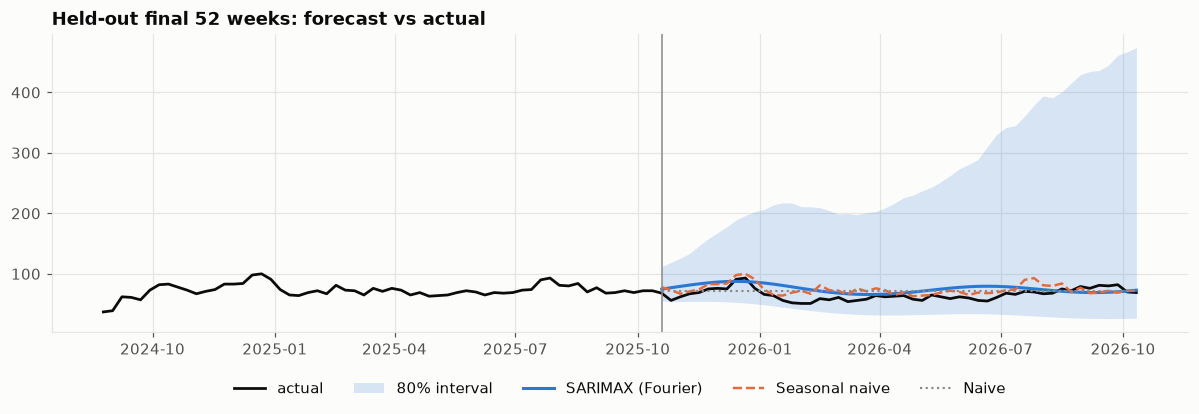

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.9))
ax.plot(weeks[T - 60:], y[T - 60:], color=viz.INK, lw=1.8, label="actual")
m, lo, hi = hold_pred[best]
ax.fill_between(weeks[T:], lo, hi, color=viz.SERIES[0], alpha=0.18, lw=0, label="80% interval")
ax.plot(weeks[T:], m, color=viz.SERIES[0], lw=2, label=best)
ax.plot(weeks[T:], hold_pred["Seasonal naive (52w)"][0], color=viz.SERIES[1], lw=1.6, ls="--", label="Seasonal naive")
ax.plot(weeks[T:], hold_pred["Naive (last week)"][0], color=viz.NEUTRAL, lw=1.4, ls=":", label="Naive")
ax.axvline(weeks[T], color=viz.NEUTRAL, lw=1); ax.set_title("Held-out final 52 weeks: forecast vs actual"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(FIG / "forecast_holdout.png", dpi=150); plt.show()

## 3 · Changepoints: when did the craze change gear?

`ruptures` (PELT, L2 cost) on the log series after a 3-week median to calm spikes. The penalty controls how many breaks appear, so the sensitivity table is part of the result, not an afterthought. Detected breaks are matched to the nearest product event within ±8 weeks.

In [8]:
# remove the annual cycle first, otherwise PELT happily "detects" every December
tt = (weeks - pd.Timestamp("2018-01-01")).days.values / 7.0
Fm = np.column_stack([f(2 * np.pi * k * tt / PERIOD) for k in (1, 2) for f in (np.sin, np.cos)])
detr = ly - pd.Series(ly).rolling(53, center=True, min_periods=26).mean().values
ok = ~np.isnan(detr)
season = Fm @ np.linalg.lstsq(Fm[ok], detr[ok], rcond=None)[0]
des = ly - season
sig = pd.Series(des).rolling(3, center=True, min_periods=1).median().values.reshape(-1, 1)
sigma2 = np.var(np.diff(des)) / 2                                      # noise variance from first differences
n = len(sig)
def detect(mult):
    bk = rpt.Pelt(model="l2", min_size=8, jump=1).fit(sig).predict(pen=mult * np.log(n) * sigma2)
    return [b for b in bk if b < n]

sens = pd.DataFrame({m_: [len(detect(m_))] for m_ in [2, 5, 10, 20, 40, 80]}, index=["n changepoints"])
print("Penalty multiplier -> number of changepoints"); print(sens.to_string())

Penalty multiplier -> number of changepoints
                2   5   10  20  40  80
n changepoints  14   7   6   5   5   3


In [9]:
PEN = 10   # middle of the plateau in the table above (count is stable across 10-20), chosen without looking at event dates
cp_idx = detect(PEN)
cps = pd.DataFrame({"date": weeks[cp_idx]})
ev = events.copy()
def nearest(d):
    gaps = (ev["date"] - d).dt.days / 7.0
    i = gaps.abs().idxmin()
    return pd.Series({"event": ev.loc[i, "label"], "event_type": ev.loc[i, "type"], "gap_weeks": round(float(gaps[i]), 1)})
cps = pd.concat([cps, cps["date"].apply(nearest)], axis=1)
cps["matched"] = cps["gap_weeks"].abs() <= 8
print(f"{len(cps)} changepoints, {cps.matched.mean():.0%} within 8 weeks of a product event")

# size of the level shift (4 weeks after vs 4 before, in %)
def shift(i): return 100 * (np.exp(ly[i:i + 6].mean() - ly[max(i - 6, 0):i].mean()) - 1)
cps["level_shift_pct"] = [round(shift(i), 0) for i in cp_idx]
cps

6 changepoints, 67% within 8 weeks of a product event


,date,event,event_type,gap_weeks,matched,level_shift_pct
0,2021-10-10,SMISKI has gone to work! ?? The long-awaited n...,product,17.3,False,59.0
1,2022-07-10,Smiski is changing his clothes and is a little...,product,16.3,False,91.0
2,2022-12-11,"""SMISKI"" attaches to your Zipper and watches o...",product,4.9,True,98.0
3,2023-05-14,Have fun exercising with Smiski! New Release：『...,product,1.6,True,348.0
4,2024-01-14,Moving from corner to corner? New Release：『SMI...,product,0.3,True,35.0
5,2024-09-08,"""SMISKI"" is now available as the popular decor...",product,0.4,True,86.0


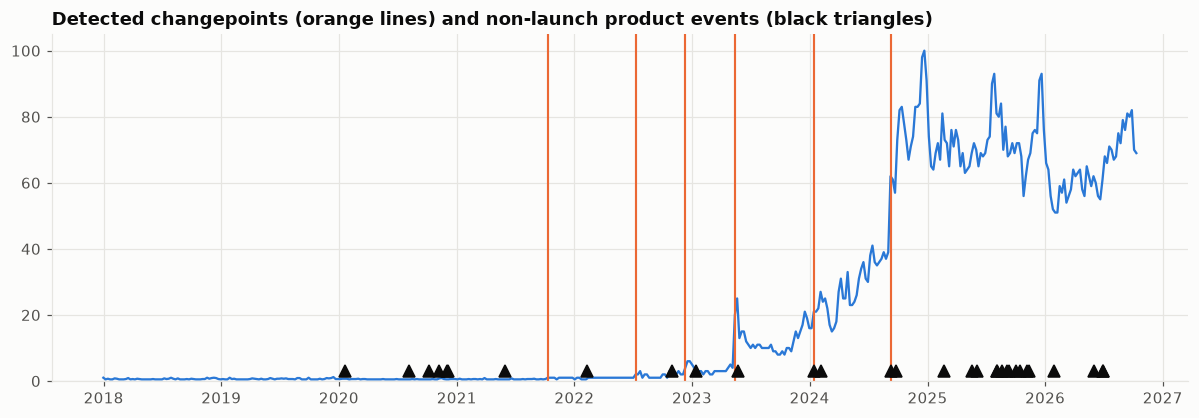

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.9))
ax.plot(weeks, y, color=viz.SERIES[0], lw=1.5)
for d in cps["date"]: ax.axvline(d, color=viz.SERIES[1], lw=1.4)
for _, e in events[events.type != "series_launch"].iterrows():
    ax.plot([e["date"]], [3], marker="^", ms=8, color=viz.INK, ls="")
ax.set_title("Detected changepoints (orange lines) and non-launch product events (black triangles)"); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig(FIG / "forecast_changepoints.png", dpi=150); plt.show()

# Validation only possible on simulated data, where the true structural breaks are known.
prov = provenance()
truth = prov.get("level_steps_ground_truth")
validation = None
if prov["tables"].get("trends") == "simulated" and truth:
    td = pd.to_datetime([t[0] for t in truth])
    found = [(abs((weeks[cp_idx] - t).days) / 7 <= 8).any() for t in td]
    validation = dict(true_breaks=len(td), recovered_within_8w=int(sum(found)))
    print("SIMULATED-DATA CHECK: recovered", validation["recovered_within_8w"], "of", validation["true_breaks"], "injected structural breaks")

## 4 · Final forecast: the next 26 weeks

Refit the chosen model on **all** data. The calendar contains only launches that already happened, so this forecast assumes **no new series launch** in the window.

/Users/johnwesleypabalate/smiskis/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/johnwesleypabalate/smiskis/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
seasonal peak: December (+28% vs trend)


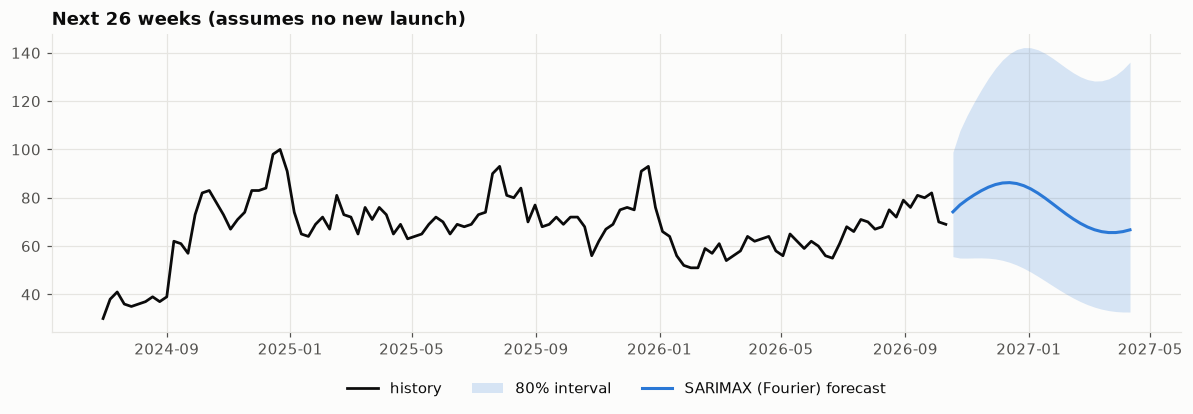

In [11]:
F = 26
fi = pd.date_range(weeks[-1] + pd.Timedelta(weeks=1), periods=F, freq="W-SUN")
fm, nl, nh = MODELS[best](weeks, y, F)
q10f, q90f, _ = calibrated(MODELS[best], weeks, y, F)
fl, fh = np.minimum(nl, fm * np.exp(q10f)), np.maximum(nh, fm * np.exp(q90f))

fig, ax = plt.subplots(figsize=(11, 3.9))
ax.plot(weeks[-120:], y[-120:], color=viz.INK, lw=1.8, label="history")
ax.fill_between(fi, fl, fh, color=viz.SERIES[0], alpha=0.18, lw=0, label="80% interval")
ax.plot(fi, fm, color=viz.SERIES[0], lw=2, label=f"{best} forecast")
ax.set_title(f"Next {F} weeks (assumes no new launch)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(FIG / "forecast_future.png", dpi=150); plt.show()

# seasonal peak month from detrended log series
detr = pd.Series(ly, index=weeks) - pd.Series(ly, index=weeks).rolling(53, center=True, min_periods=26).mean()
by_month = detr.groupby(detr.index.month).mean()
peak_m = int(by_month.idxmax()); month_name = pd.Timestamp(2000, peak_m, 1).strftime("%B")
print("seasonal peak:", month_name, f"(+{100*(np.exp(by_month.max())-1):.0f}% vs trend)")

In [12]:
nv, sv = hold.loc["Naive (last week)"], hold.loc["Seasonal naive (52w)"]
b = hold.loc[best]
takeaways = [
    f"Chosen model: {best} (picked on rolling-origin backtests, not on the hold-out).",
    f"On the held-out final {HOLD} weeks it has MAE {b.MAE:.1f} vs {nv.MAE:.1f} (naive) and {sv.MAE:.1f} (seasonal naive): "
    f"{b['MAE vs naive']:+.0%} vs naive, {b['MAE vs seasonal naive']:+.0%} vs seasonal naive.",
    f"Interval coverage on the hold-out (target 80%): the model's built-in interval {native_cov:.0%}, an empirical one from {n_or} backtest origins {emp_cov:.0%}; the plotted band is the wider of the two and covers {b['coverage80']:.0%}" + (" (too wide to be sharp)." if b['coverage80'] > 0.92 else " (still too narrow)." if b['coverage80'] < 0.7 else "."),
    ("Verdict: no model beat plain 'same as last week' on the hold-out, so use the naive forecast and treat anything fancier as unproven." if b["MAE vs naive"] <= 0 else
     f"Verdict: the chosen model beats 'same as last week' by {b['MAE vs naive']:.0%} on the hold-out."),
    f"{cps.matched.sum()} of {len(cps)} detected changepoints sit within 8 weeks of a known product event; interest is seasonal with a peak around {month_name}.",
    "The 26-week forecast assumes no new series launch; a launch would push the real line above the interval.",
]
if validation: takeaways.append(f"Simulated-data check: {validation['recovered_within_8w']} of {validation['true_breaks']} injected breaks recovered.")
for t in takeaways: print("-", t)

iso = lambda idx: [d.strftime("%Y-%m-%d") for d in idx]
rnd = lambda a: [None if a is None else round(float(v), 1) for v in a]
out = dict(
    provenance=prov["tables"], as_of=AS_OF, holdout_weeks=HOLD, chosen_model=best,
    history=dict(dates=iso(weeks), values=[int(v) for v in y]),
    holdout=dict(dates=iso(weeks[T:]),
                 models={n: dict(mean=rnd(p[0]), lo=rnd(p[1]) if p[1] is not None else None, hi=rnd(p[2]) if p[2] is not None else None) for n, p in hold_pred.items()}),
    future=dict(dates=iso(fi), mean=rnd(fm), lo=rnd(fl), hi=rnd(fh)),
    metrics=[dict(model=n, mae=round(r.MAE, 2), rmse=round(r.RMSE, 2), smape=round(r.sMAPE, 1), mase=round(r.MASE, 2),
                  coverage=None if "coverage80" not in r or pd.isna(r.get("coverage80")) else round(float(r["coverage80"]), 2),
                  backtest_mase=round(float(bt_summary.loc[n, "MASE"]), 2)) for n, r in hold.iterrows()],
    changepoints=[dict(date=r.date.strftime("%Y-%m-%d"), event=r.event, type=r.event_type, gap_weeks=r.gap_weeks, matched=bool(r.matched), shift_pct=r.level_shift_pct) for r in cps.itertuples()],
    events=[dict(date=r.date.strftime("%Y-%m-%d"), type=r.type, label=r.label) for r in events.itertuples()],
    seasonal_peak=month_name, validation=validation, takeaways=takeaways,
)
(SITE_DATA / "forecast.json").write_text(json.dumps(out))
print("wrote", SITE_DATA / "forecast.json")

- Chosen model: SARIMAX (Fourier) (picked on rolling-origin backtests, not on the hold-out).
- On the held-out final 52 weeks it has MAE 11.8 vs 9.6 (naive) and 9.8 (seasonal naive): -22% vs naive, -21% vs seasonal naive.
- Interval coverage on the hold-out (target 80%): the model's built-in interval 100%, an empirical one from 14 backtest origins 2%; the plotted band is the wider of the two and covers 100% (too wide to be sharp).
- Verdict: no model beat plain 'same as last week' on the hold-out, so use the naive forecast and treat anything fancier as unproven.
- 4 of 6 detected changepoints sit within 8 weeks of a known product event; interest is seasonal with a peak around December.
- The 26-week forecast assumes no new series launch; a launch would push the real line above the interval.
wrote /Users/johnwesleypabalate/smiskis/site/data/forecast.json


## Business takeaway

* **Plan inventory around launches and December, not the average week.** The forecast is a baseline of organic interest; launch weeks sit above it.
* **Check whether complexity paid off.** The comparison table is the answer; if the gap to *seasonal naive* is small, ship the simple method.
* **Changepoints are leads, not proof.** A break near an event is consistent with the event mattering, but several things usually happen at once.
* **If the data is simulated** (banner at the top), the "events" and "breaks" are inputs to the generator, so a good match only shows the method works.